In [1]:
import os
import gzip
import struct
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError("Activer un GPU dans les paramètres du notebook Kaggle.")

torch.backends.cudnn.benchmark = True
WORKDIR = Path("/kaggle/working")
FIGDIR = WORKDIR / "figures_part2"
FIGDIR.mkdir(parents=True, exist_ok=True)
NUM_WORKERS = 2

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Nombre de GPU:", torch.cuda.device_count())

PyTorch: 2.11.0+cu128
GPU: Tesla T4
Nombre de GPU: 2


In [2]:
input_root = Path("/kaggle/input")
all_input_files = sorted(p for p in input_root.rglob("*") if p.is_file())

def find_idx_file(split, kind):
    prefix = f"{split}-{kind}"
    candidates = [
        p for p in all_input_files
        if p.name.lower().startswith(prefix) and "ubyte" in p.name.lower()
    ]
    if not candidates:
        raise FileNotFoundError(f"Fichier MNIST introuvable: {prefix}")
    return candidates[0]

def read_idx(path):
    if str(path).lower().endswith(".gz"):
        with gzip.open(path, "rb") as f:
            content = f.read()
    else:
        content = path.read_bytes()
    magic = struct.unpack(">I", content[:4])[0]
    if magic == 2051:
        count, height, width = struct.unpack(">III", content[4:16])
        return np.frombuffer(content, dtype=np.uint8, offset=16).reshape(count, height, width).copy()
    if magic == 2049:
        count = struct.unpack(">I", content[4:8])[0]
        return np.frombuffer(content, dtype=np.uint8, offset=8).reshape(count).copy()
    raise ValueError(f"Format IDX non reconnu: {path}")

train_images = read_idx(find_idx_file("train", "images"))
train_labels = read_idx(find_idx_file("train", "labels"))
test_images = read_idx(find_idx_file("t10k", "images"))
test_labels = read_idx(find_idx_file("t10k", "labels"))

assert train_images.shape == (60000, 28, 28)
assert test_images.shape == (10000, 28, 28)
assert len(train_labels) == 60000 and len(test_labels) == 10000

print("Training:", train_images.shape, train_labels.shape)
print("Test:", test_images.shape, test_labels.shape)
print("Classes:", np.unique(train_labels))

Training: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)
Classes: [0 1 2 3 4 5 6 7 8 9]


In [3]:
class MNISTDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.from_numpy(images)
        self.labels = torch.from_numpy(labels.astype(np.int64))

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = self.images[index].float().unsqueeze(0) / 255.0
        image = (image - 0.1307) / 0.3081
        return image, self.labels[index]

BATCH_SIZE = 256
train_dataset = MNISTDataset(train_images, train_labels)
test_dataset = MNISTDataset(test_images, test_labels)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

print("Train samples:", len(train_dataset))
print("Test samples:", len(test_dataset))
print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

Train samples: 60000
Test samples: 10000
Train batches: 235
Test batches: 40


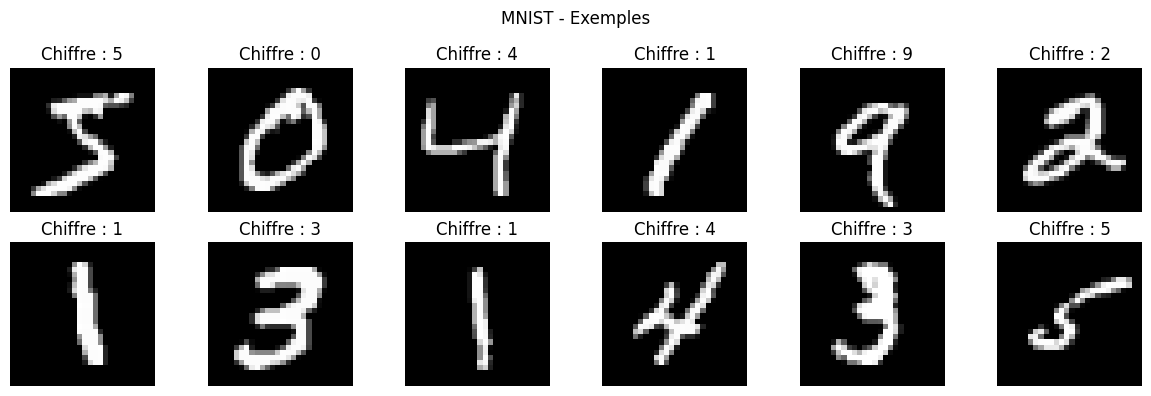

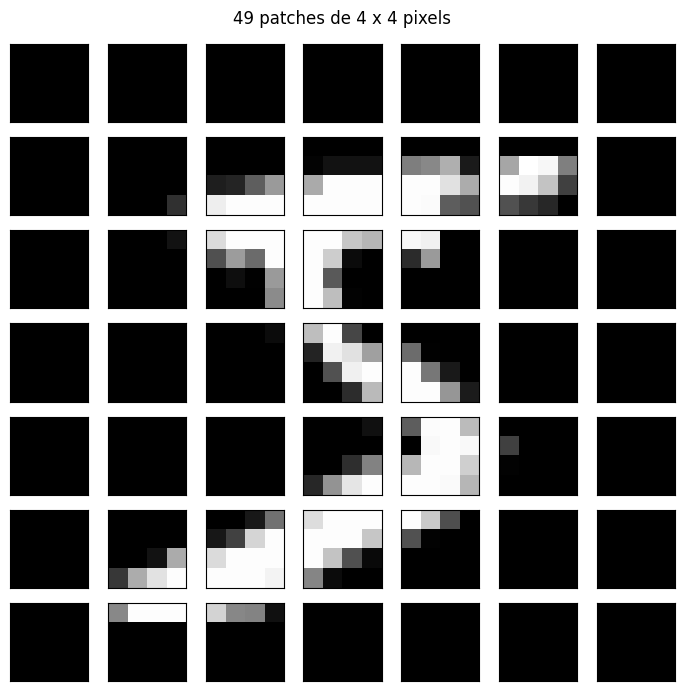

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for index, ax in enumerate(axes.flat):
    ax.imshow(train_images[index], cmap="gray")
    ax.set_title(f"Chiffre : {int(train_labels[index])}")
    ax.axis("off")
plt.suptitle("MNIST - Exemples")
plt.tight_layout()
plt.savefig(FIGDIR / "mnist_exemples_vit.png", dpi=160, bbox_inches="tight")
plt.show()

patch_size = 4
example_image = train_images[0]
patches = example_image.reshape(7, patch_size, 7, patch_size).transpose(0, 2, 1, 3).reshape(49, patch_size, patch_size)

fig, axes = plt.subplots(7, 7, figsize=(7, 7))
for index, ax in enumerate(axes.flat):
    ax.imshow(patches[index], cmap="gray", vmin=0, vmax=255)
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("49 patches de 4 x 4 pixels")
plt.tight_layout()
plt.savefig(FIGDIR / "vit_patches.png", dpi=160, bbox_inches="tight")
plt.show()

In [5]:
class PatchEmbedding(nn.Module):
    def __init__(self, image_size=28, patch_size=4, embed_dim=128):
        super().__init__()
        assert image_size % patch_size == 0
        self.unfold = nn.Unfold(kernel_size=patch_size, stride=patch_size)
        self.projection = nn.Linear(patch_size * patch_size, embed_dim)
        self.num_patches = (image_size // patch_size) ** 2

    def forward(self, images):
        patches = self.unfold(images).transpose(1, 2)
        return self.projection(patches)

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim=128, num_heads=4, dropout=0.1):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = nn.Linear(embed_dim, embed_dim * 3)
        self.attention_dropout = nn.Dropout(dropout)
        self.output_projection = nn.Linear(embed_dim, embed_dim)
        self.output_dropout = nn.Dropout(dropout)

    def forward(self, x):
        batch_size, num_tokens, embed_dim = x.shape
        qkv = self.qkv(x).reshape(
            batch_size, num_tokens, 3, self.num_heads, self.head_dim
        ).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(dim=0)
        attention = (q @ k.transpose(-2, -1)) * self.scale
        attention = torch.softmax(attention, dim=-1)
        attention = self.attention_dropout(attention)
        output = (attention @ v).transpose(1, 2).reshape(batch_size, num_tokens, embed_dim)
        return self.output_dropout(self.output_projection(output))

class TransformerEncoderBlock(nn.Module):
    def __init__(self, embed_dim=128, num_heads=4, mlp_dim=256, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attention = MultiHeadSelfAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, mlp_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_dim, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x

class MNISTViT(nn.Module):
    def __init__(
        self,
        image_size=28,
        patch_size=4,
        embed_dim=128,
        num_heads=4,
        depth=4,
        mlp_dim=256,
        dropout=0.1,
        num_classes=10
    ):
        super().__init__()
        self.patch_embedding = PatchEmbedding(image_size, patch_size, embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embedding = nn.Parameter(
            torch.zeros(1, self.patch_embedding.num_patches + 1, embed_dim)
        )
        self.embedding_dropout = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[
            TransformerEncoderBlock(embed_dim, num_heads, mlp_dim, dropout)
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)
        self.classifier = nn.Linear(embed_dim, num_classes)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)

    def forward(self, images):
        x = self.patch_embedding(images)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat([cls, x], dim=1)
        x = self.embedding_dropout(x + self.pos_embedding)
        x = self.blocks(x)
        x = self.norm(x)
        return self.classifier(x[:, 0])

In [6]:
vit_config = {
    "image_size": 28,
    "patch_size": 4,
    "embed_dim": 128,
    "num_heads": 4,
    "depth": 4,
    "mlp_dim": 256,
    "dropout": 0.1,
    "num_classes": 10
}

vit_model = MNISTViT(**vit_config).to(DEVICE)
num_parameters = sum(p.numel() for p in vit_model.parameters() if p.requires_grad)

with torch.inference_mode():
    example_output = vit_model(torch.zeros(2, 1, 28, 28, device=DEVICE))

assert example_output.shape == (2, 10)

print(vit_model)
print("Trainable Parameters:", num_parameters)
print("Number of patches:", vit_model.patch_embedding.num_patches)
print("Output Shape:", tuple(example_output.shape))

MNISTViT(
  (patch_embedding): PatchEmbedding(
    (unfold): Unfold(kernel_size=4, dilation=1, padding=0, stride=4)
    (projection): Linear(in_features=16, out_features=128, bias=True)
  )
  (embedding_dropout): Dropout(p=0.1, inplace=False)
  (blocks): Sequential(
    (0): TransformerEncoderBlock(
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (attention): MultiHeadSelfAttention(
        (qkv): Linear(in_features=128, out_features=384, bias=True)
        (attention_dropout): Dropout(p=0.1, inplace=False)
        (output_projection): Linear(in_features=128, out_features=128, bias=True)
        (output_dropout): Dropout(p=0.1, inplace=False)
      )
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (mlp): Sequential(
        (0): Linear(in_features=128, out_features=256, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.1, inplace=False)
        (3): Linear(in_features=256, out_features=128, bias=True)
       

In [7]:
criterion = nn.CrossEntropyLoss()

@torch.inference_mode()
def evaluate_vit(model, loader):
    model.eval()
    total_loss = 0.0
    total_count = 0
    y_true = []
    y_pred = []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)
            loss = criterion(logits, labels)
        total_loss += loss.item() * labels.size(0)
        total_count += labels.size(0)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(logits.argmax(dim=1).cpu().numpy())

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "loss": total_loss / total_count,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=list(range(10)), average="macro", zero_division=0),
        "y_true": y_true,
        "y_pred": y_pred
    }

EPOCHS = 12
LEARNING_RATE = 0.0005

optimizer = torch.optim.AdamW(
    vit_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=0.00001
)

scaler = torch.amp.GradScaler("cuda")

vit_history = {
    "train_loss": [],
    "train_accuracy": [],
    "test_loss": [],
    "test_accuracy": [],
    "test_macro_f1": [],
    "epoch_training_time": []
}

print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)

Epochs: 12
Batch Size: 256
Learning Rate: 0.0005


In [8]:
training_time = 0.0

for epoch in range(EPOCHS):
    vit_model.train()
    total_loss = 0.0
    total_correct = 0
    total_count = 0

    torch.cuda.synchronize()
    start = time.perf_counter()

    for images, labels in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = vit_model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(vit_model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_count += labels.size(0)

    torch.cuda.synchronize()
    epoch_training_time = time.perf_counter() - start
    training_time += epoch_training_time
    scheduler.step()

    train_loss = total_loss / total_count
    train_accuracy = total_correct / total_count
    test_metrics = evaluate_vit(vit_model, test_loader)

    vit_history["train_loss"].append(train_loss)
    vit_history["train_accuracy"].append(train_accuracy)
    vit_history["test_loss"].append(test_metrics["loss"])
    vit_history["test_accuracy"].append(test_metrics["accuracy"])
    vit_history["test_macro_f1"].append(test_metrics["macro_f1"])
    vit_history["epoch_training_time"].append(epoch_training_time)

    print(
        f"ViT | Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Test Loss: {test_metrics['loss']:.4f} | "
        f"Test Acc: {test_metrics['accuracy']:.4f} | "
        f"Test Macro F1: {test_metrics['macro_f1']:.4f} | "
        f"Time: {epoch_training_time:.1f}s | "
        f"Train Images: {total_count}"
    )

print("Total Training Time (s):", round(training_time, 2))

ViT | Epoch 1/12 | Train Loss: 1.3436 | Train Acc: 0.5123 | Test Loss: 0.6652 | Test Acc: 0.7748 | Test Macro F1: 0.7679 | Time: 5.7s | Train Images: 60000
ViT | Epoch 2/12 | Train Loss: 0.5614 | Train Acc: 0.8107 | Test Loss: 0.3333 | Test Acc: 0.8931 | Test Macro F1: 0.8912 | Time: 4.9s | Train Images: 60000
ViT | Epoch 3/12 | Train Loss: 0.3320 | Train Acc: 0.8920 | Test Loss: 0.2396 | Test Acc: 0.9248 | Test Macro F1: 0.9238 | Time: 5.0s | Train Images: 60000
ViT | Epoch 4/12 | Train Loss: 0.2374 | Train Acc: 0.9239 | Test Loss: 0.1738 | Test Acc: 0.9433 | Test Macro F1: 0.9427 | Time: 5.3s | Train Images: 60000
ViT | Epoch 5/12 | Train Loss: 0.1781 | Train Acc: 0.9425 | Test Loss: 0.1191 | Test Acc: 0.9626 | Test Macro F1: 0.9623 | Time: 5.1s | Train Images: 60000
ViT | Epoch 6/12 | Train Loss: 0.1443 | Train Acc: 0.9537 | Test Loss: 0.1150 | Test Acc: 0.9638 | Test Macro F1: 0.9635 | Time: 4.9s | Train Images: 60000
ViT | Epoch 7/12 | Train Loss: 0.1192 | Train Acc: 0.9625 | Test

In [9]:
final_metrics = evaluate_vit(vit_model, test_loader)
vit_confusion = confusion_matrix(
    final_metrics["y_true"],
    final_metrics["y_pred"],
    labels=list(range(10))
)

print("ViT - Test Accuracy:", round(final_metrics["accuracy"], 4))
print("ViT - Test Macro F1:", round(final_metrics["macro_f1"], 4))
print("ViT - Test Loss:", round(final_metrics["loss"], 4))
print("ViT - Training Time (s):", round(training_time, 2))
print("Train Samples:", len(train_dataset))
print("Test Samples:", len(test_dataset))

print(classification_report(
    final_metrics["y_true"],
    final_metrics["y_pred"],
    labels=list(range(10)),
    zero_division=0,
    digits=4
))

class_results = pd.DataFrame({
    "Class": range(10),
    "Support": np.bincount(final_metrics["y_true"], minlength=10),
    "Predicted": np.bincount(final_metrics["y_pred"], minlength=10)
})
display(class_results)

ViT - Test Accuracy: 0.9779
ViT - Test Macro F1: 0.9777
ViT - Test Loss: 0.0726
ViT - Training Time (s): 60.94
Train Samples: 60000
Test Samples: 10000
              precision    recall  f1-score   support

           0     0.9759    0.9908    0.9833       980
           1     0.9895    0.9930    0.9912      1135
           2     0.9722    0.9816    0.9769      1032
           3     0.9849    0.9663    0.9755      1010
           4     0.9745    0.9745    0.9745       982
           5     0.9787    0.9776    0.9781       892
           6     0.9792    0.9823    0.9807       958
           7     0.9825    0.9825    0.9825      1028
           8     0.9646    0.9784    0.9715       974
           9     0.9756    0.9504    0.9629      1009

    accuracy                         0.9779     10000
   macro avg     0.9777    0.9777    0.9777     10000
weighted avg     0.9779    0.9779    0.9779     10000



,Class,Support,Predicted
0,0,980,995
1,1,1135,1139
2,2,1032,1042
3,3,1010,991
4,4,982,982
5,5,892,891
6,6,958,961
7,7,1028,1028
8,8,974,988
9,9,1009,983


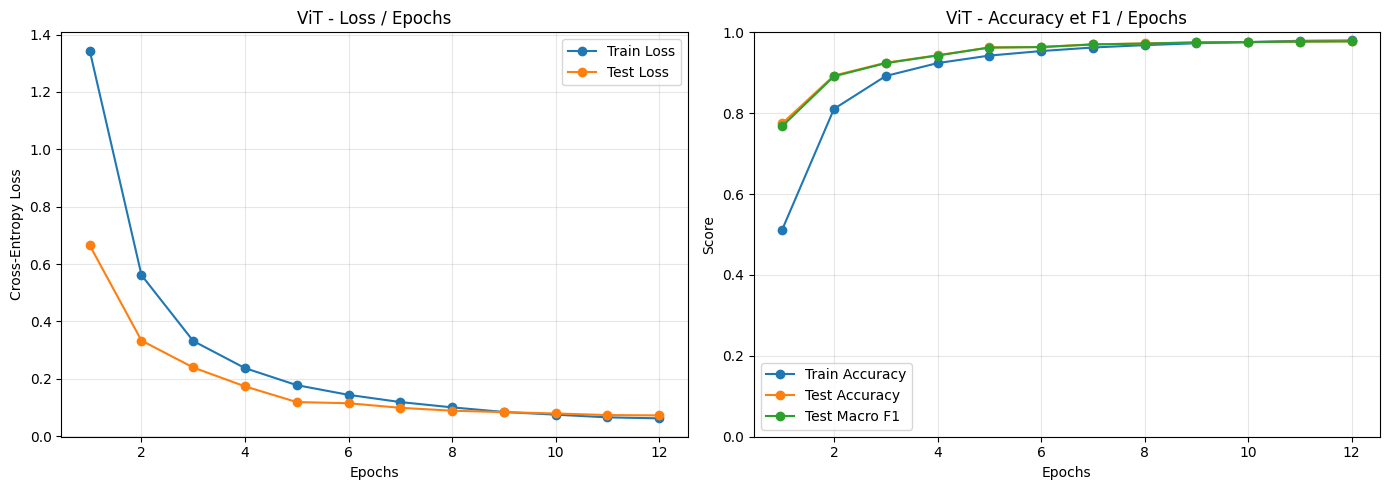

,Epoch,Train Loss,Train Accuracy,Test Loss,Test Accuracy,Test Macro F1,Training Time (s)
0,1,1.3436,0.5124,0.6652,0.7748,0.7679,5.7437
1,2,0.5614,0.8107,0.3333,0.8931,0.8912,4.8585
2,3,0.3320,0.8920,0.2396,0.9248,0.9238,5.0489
3,4,0.2374,0.9239,0.1738,0.9433,0.9427,5.2632
4,5,0.1781,0.9425,0.1191,0.9626,0.9623,5.0961
5,6,0.1443,0.9537,0.1150,0.9638,0.9635,4.9224
6,7,0.1192,0.9625,0.0992,0.9703,0.9700,4.9311
7,8,0.1007,0.9683,0.0891,0.9725,0.9722,5.0462
8,9,0.0846,0.9729,0.0840,0.9751,0.9749,4.8990
9,10,0.0753,0.9760,0.0794,0.9759,0.9757,4.9757


In [10]:
epochs_axis = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_axis, vit_history["train_loss"], marker="o", label="Train Loss")
axes[0].plot(epochs_axis, vit_history["test_loss"], marker="o", label="Test Loss")
axes[0].set_title("ViT - Loss / Epochs")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epochs_axis, vit_history["train_accuracy"], marker="o", label="Train Accuracy")
axes[1].plot(epochs_axis, vit_history["test_accuracy"], marker="o", label="Test Accuracy")
axes[1].plot(epochs_axis, vit_history["test_macro_f1"], marker="o", label="Test Macro F1")
axes[1].set_title("ViT - Accuracy et F1 / Epochs")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGDIR / "vit_courbes.png", dpi=160, bbox_inches="tight")
plt.show()

history_df = pd.DataFrame({
    "Epoch": epochs_axis,
    "Train Loss": vit_history["train_loss"],
    "Train Accuracy": vit_history["train_accuracy"],
    "Test Loss": vit_history["test_loss"],
    "Test Accuracy": vit_history["test_accuracy"],
    "Test Macro F1": vit_history["test_macro_f1"],
    "Training Time (s)": vit_history["epoch_training_time"]
})
display(history_df.round(4))

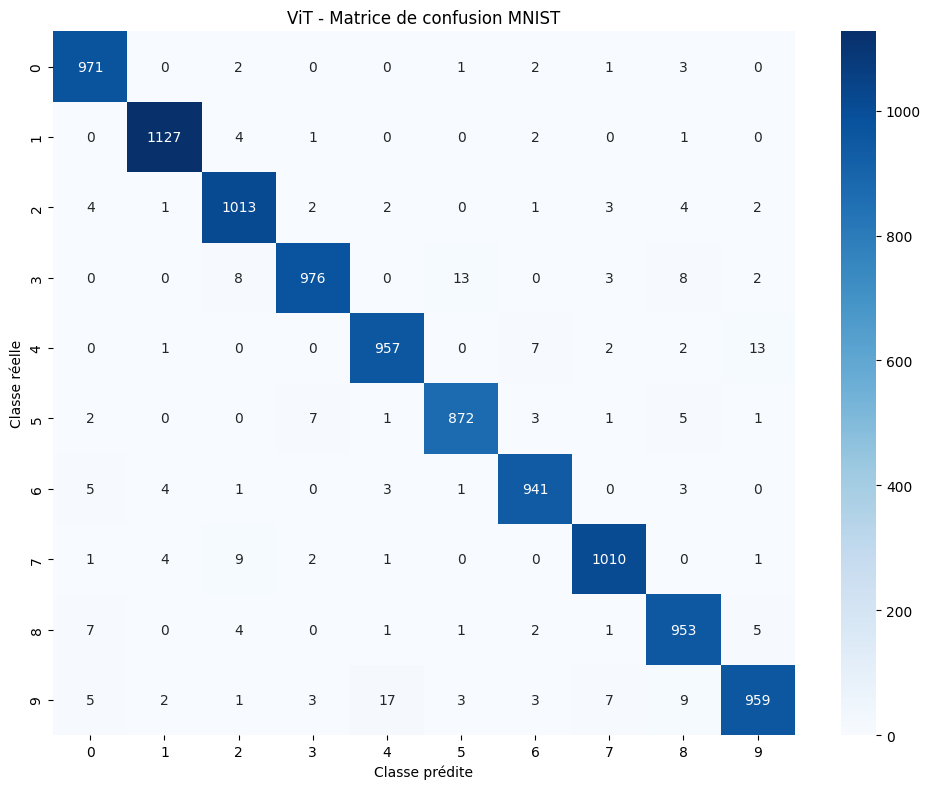

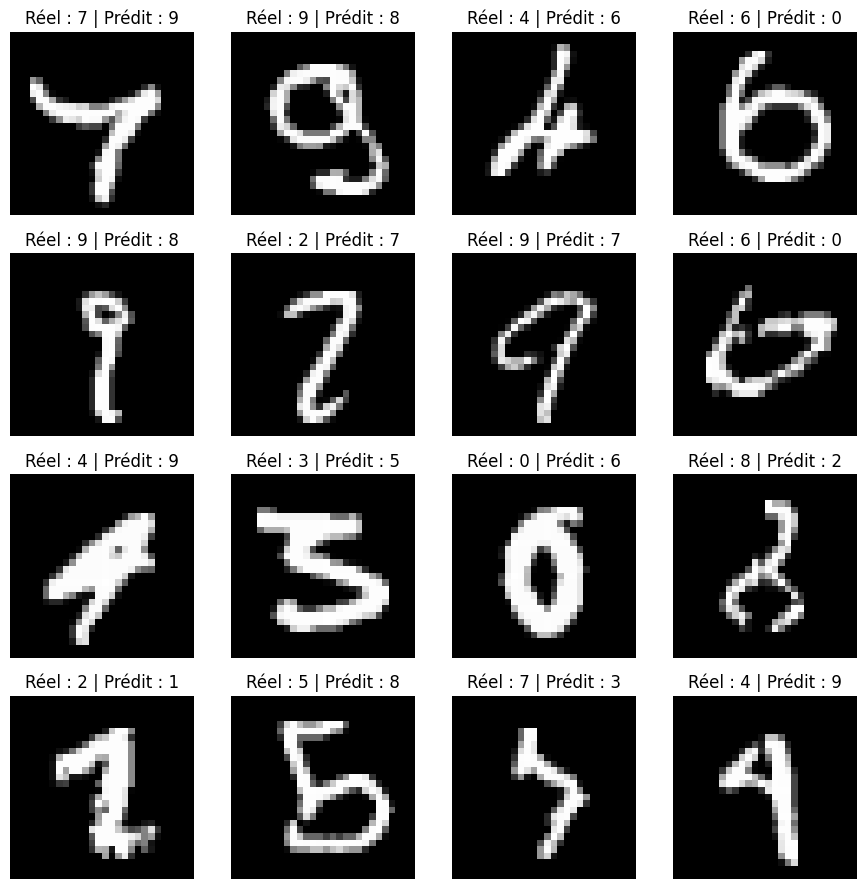

Total des erreurs: 221


In [11]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    vit_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=list(range(10)),
    yticklabels=list(range(10))
)
plt.title("ViT - Matrice de confusion MNIST")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.tight_layout()
plt.savefig(FIGDIR / "vit_confusion.png", dpi=160, bbox_inches="tight")
plt.show()

incorrect_indices = np.flatnonzero(
    final_metrics["y_true"] != final_metrics["y_pred"]
)

if len(incorrect_indices) > 0:
    examples = incorrect_indices[:16]
    fig, axes = plt.subplots(4, 4, figsize=(9, 9))
    for ax, index in zip(axes.flat, examples):
        ax.imshow(test_images[index], cmap="gray")
        ax.set_title(
            f"Réel : {final_metrics['y_true'][index]} | "
            f"Prédit : {final_metrics['y_pred'][index]}"
        )
        ax.axis("off")
    for ax in axes.flat[len(examples):]:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(FIGDIR / "vit_erreurs.png", dpi=160, bbox_inches="tight")
    plt.show()

print("Total des erreurs:", len(incorrect_indices))

Résultats réels de Part 1 repris du notebook exécuté précédemment.


,Model,Accuracy,Macro F1,Train Loss,Test Loss,Training Time (s),Epochs
0,VGG16,0.9943,0.9942,0.0185,0.0223,1143.7491,3
1,AlexNet,0.9941,0.9941,0.0153,0.0190,203.4510,3
2,CNN,0.9911,0.9910,0.0366,0.0286,46.4399,5
3,Faster R-CNN,0.9840,0.9839,0.3141,0.3348,1638.0305,2
4,ViT (from scratch),0.9779,0.9777,0.0624,0.0726,60.9362,12


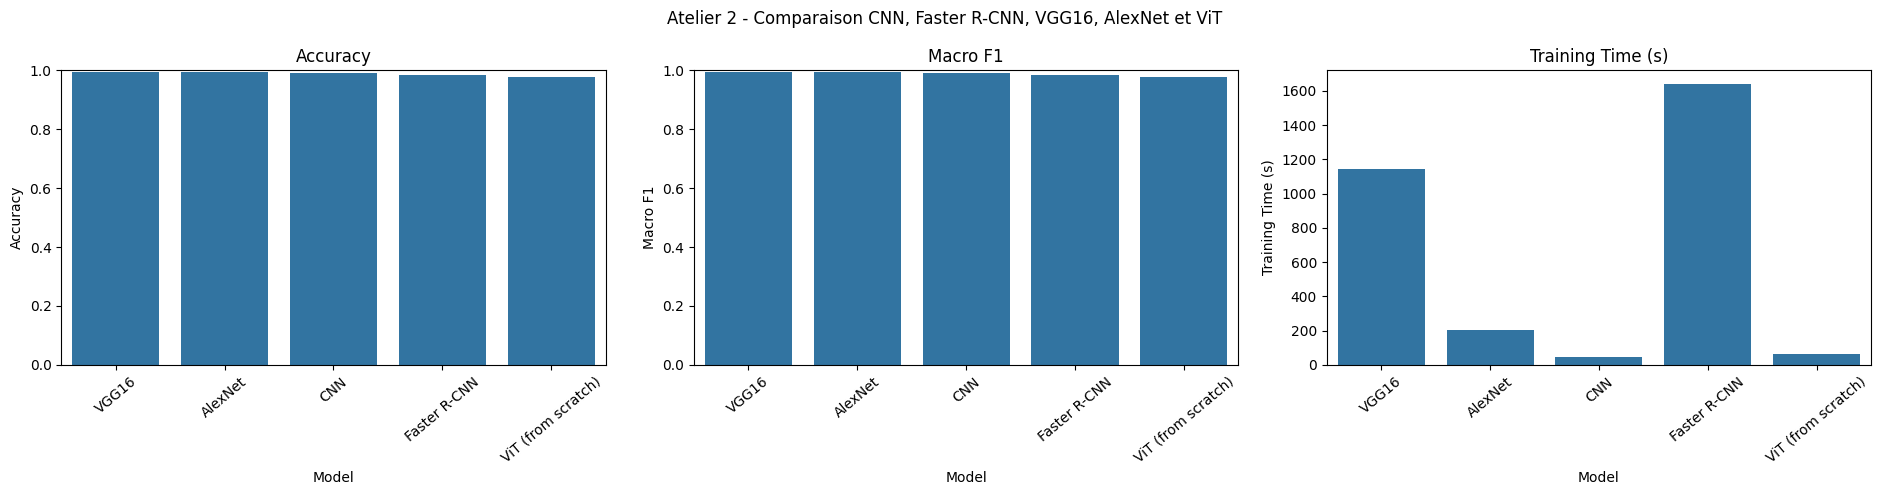

Meilleur modèle selon Macro F1: VGG16
La comparaison des temps dépend des architectures, du pré-entraînement et du nombre d'epochs.
Les Loss de Faster R-CNN et des modèles de classification ne sont pas directement comparables.


In [12]:
part1_results_path = None
for location in [Path("/kaggle/working/atelier2_part1_comparaison.csv"), *Path("/kaggle/input").rglob("atelier2_part1_comparaison.csv")]:
    if location.is_file():
        part1_results_path = location
        break

if part1_results_path is not None:
    part1_comparison = pd.read_csv(part1_results_path)
    print("Résultats Part 1 chargés depuis:", part1_results_path)
else:
    part1_comparison = pd.DataFrame([
        {"Model": "VGG16", "Accuracy": 0.9943, "Macro F1": 0.9942, "Train Loss": 0.0185, "Test Loss": 0.0223, "Training Time (s)": 1143.7491, "Epochs": 3},
        {"Model": "AlexNet", "Accuracy": 0.9941, "Macro F1": 0.9941, "Train Loss": 0.0153, "Test Loss": 0.0190, "Training Time (s)": 203.4510, "Epochs": 3},
        {"Model": "CNN", "Accuracy": 0.9911, "Macro F1": 0.9910, "Train Loss": 0.0366, "Test Loss": 0.0286, "Training Time (s)": 46.4399, "Epochs": 5},
        {"Model": "Faster R-CNN", "Accuracy": 0.9840, "Macro F1": 0.9839, "Train Loss": 0.3141, "Test Loss": 0.3348, "Training Time (s)": 1638.0305, "Epochs": 2}
    ])
    print("Résultats réels de Part 1 repris du notebook exécuté précédemment.")

vit_row = pd.DataFrame([{
    "Model": "ViT (from scratch)",
    "Accuracy": final_metrics["accuracy"],
    "Macro F1": final_metrics["macro_f1"],
    "Train Loss": vit_history["train_loss"][-1],
    "Test Loss": final_metrics["loss"],
    "Training Time (s)": training_time,
    "Epochs": EPOCHS
}])

comparison_final = pd.concat(
    [part1_comparison, vit_row],
    ignore_index=True
).sort_values("Macro F1", ascending=False).reset_index(drop=True)

display(comparison_final[[
    "Model", "Accuracy", "Macro F1", "Train Loss",
    "Test Loss", "Training Time (s)", "Epochs"
]].round(4))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, metric in zip(axes, ["Accuracy", "Macro F1", "Training Time (s)"]):
    sns.barplot(data=comparison_final, x="Model", y=metric, ax=ax)
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=40)
    if metric != "Training Time (s)":
        ax.set_ylim(0, 1)

plt.suptitle("Atelier 2 - Comparaison CNN, Faster R-CNN, VGG16, AlexNet et ViT")
plt.tight_layout()
plt.savefig(FIGDIR / "comparaison_part1_part2.png", dpi=160, bbox_inches="tight")
plt.show()

print("Meilleur modèle selon Macro F1:", comparison_final.iloc[0]["Model"])
print("La comparaison des temps dépend des architectures, du pré-entraînement et du nombre d'epochs.")
print("Les Loss de Faster R-CNN et des modèles de classification ne sont pas directement comparables.")

In [13]:
history_df.to_csv(WORKDIR / "atelier2_part2_vit_history.csv", index=False)
comparison_final.to_csv(WORKDIR / "atelier2_comparaison_complete.csv", index=False)
class_results.to_csv(WORKDIR / "atelier2_part2_classes.csv", index=False)

summary = pd.DataFrame([{
    "Model": "ViT (from scratch)",
    "Train Images": len(train_dataset),
    "Test Images": len(test_dataset),
    "Accuracy": final_metrics["accuracy"],
    "Macro F1": final_metrics["macro_f1"],
    "Train Loss": vit_history["train_loss"][-1],
    "Test Loss": final_metrics["loss"],
    "Training Time (s)": training_time,
    "Epochs": EPOCHS,
    "Trainable Parameters": num_parameters
}])

summary.to_csv(WORKDIR / "atelier2_part2_vit_results.csv", index=False)

model_path = WORKDIR / "atelier2_part2_vit.pth"
torch.save({
    "model_state_dict": vit_model.state_dict(),
    "config": vit_config,
    "epochs": EPOCHS,
    "accuracy": final_metrics["accuracy"],
    "macro_f1": final_metrics["macro_f1"]
}, model_path)

display(summary.round(4))
print("Modèle:", model_path)
print("Fichiers enregistrés:")
for path in sorted(WORKDIR.glob("atelier2_part2*.csv")):
    print(path)
print(WORKDIR / "atelier2_comparaison_complete.csv")
for path in sorted(FIGDIR.glob("*.png")):
    print(path)

,Model,Train Images,Test Images,Accuracy,Macro F1,Train Loss,Test Loss,Training Time (s),Epochs,Trainable Parameters
0,ViT (from scratch),60000,10000,0.9779,0.9777,0.0624,0.0726,60.9362,12,540170


Modèle: /kaggle/working/atelier2_part2_vit.pth
Fichiers enregistrés:
/kaggle/working/atelier2_part2_classes.csv
/kaggle/working/atelier2_part2_vit_history.csv
/kaggle/working/atelier2_part2_vit_results.csv
/kaggle/working/atelier2_comparaison_complete.csv
/kaggle/working/figures_part2/comparaison_part1_part2.png
/kaggle/working/figures_part2/mnist_exemples_vit.png
/kaggle/working/figures_part2/vit_confusion.png
/kaggle/working/figures_part2/vit_courbes.png
/kaggle/working/figures_part2/vit_erreurs.png
/kaggle/working/figures_part2/vit_patches.png
